# SVM Tie Breaking: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/svm/plot_svm_tie_breaking.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/svm/plot_svm_tie_breaking.html)).

**Scenario:** a three-class `make_blobs(random_state=27)` problem fitted with
`SVC(kernel="linear", C=1, break_ties=False|True, decision_function_shape="ovr")`, then predicted on a
1000 x 1000 grid, with the three one-vs-one hyperplanes drawn from `coef_` and `intercept_`.

Extra checks beyond the plot: `support_`, `support_vectors_`, `n_support_`, `dual_coef_`, `intercept_`,
`coef_`, `classes_`, `n_iter_`, `fit_status_`, `shape_fit_`, OVR and OVO `decision_function` on the training
data, `score`, the `break_ties` + `"ovo"` error, and a composition section: `make_pipeline(StandardScaler(), SVC)`
plus `clone`, and the `OneVsRestClassifier(SVC())` gap.

**Adaptations:**
- Labels are shared as integers and fitted with `SVC[Int]` (typed label domain); predictions are `List[Int]`.
- `coef_` is a method `coef_()` in Moxie (documented native adaptation of sklearn's conditional property).
- The figures are smaller (dpi 80); the Moxie grid predictions are drawn in a second, paired figure.
- The Python cells use the scikit-learn wheel installed in the notebooks environment; the SVC code paths
  used here are unchanged between it and the pinned revision.

**Determinism:** deterministic. `make_blobs` is seeded, and SVC without `probability=True` consumes no
random numbers that affect the model (the seed draw only feeds Platt scaling).

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("svm/plot_svm_tie_breaking")

## 1. scikit-learn (Python reference)

The official example code, with smaller figures and the fitted models kept for comparison.

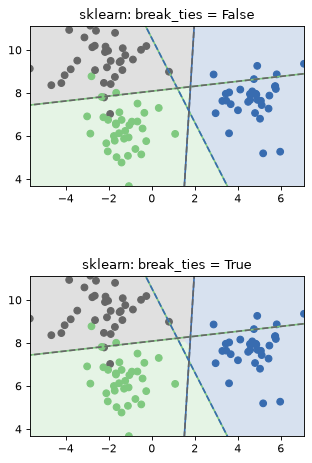

sklearn break_ties + ovo: break_ties must be False when decision_function_shape is 'ovo'
support_ sizes: [6 2 6] n_iter_: [  6 801   4]
training accuracy: 0.96


In [2]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.datasets import make_blobs
from sklearn.svm import SVC

X, y = make_blobs(random_state=27)

fig, sub = plt.subplots(2, 1, figsize=(4, 6.4), dpi=80)
titles = ("break_ties = False", "break_ties = True")

xlim = [X[:, 0].min(), X[:, 0].max()]
ylim = [X[:, 1].min(), X[:, 1].max()]
xs = np.linspace(xlim[0], xlim[1], 1000)
ys = np.linspace(ylim[0], ylim[1], 1000)
xx, yy = np.meshgrid(xs, ys)
grid = np.c_[xx.ravel(), yy.ravel()]

sk_models, sk_pred = {}, {}
for break_ties, title, ax in zip((False, True), titles, sub.flatten()):
    svm = SVC(
        kernel="linear", C=1, break_ties=break_ties, decision_function_shape="ovr"
    ).fit(X, y)
    sk_models[break_ties] = svm

    pred = svm.predict(grid)
    sk_pred[break_ties] = pred

    colors = [plt.cm.Accent(i) for i in [0, 4, 7]]

    points = ax.scatter(X[:, 0], X[:, 1], c=y, cmap="Accent")
    classes = [(0, 1), (0, 2), (1, 2)]
    line = np.linspace(X[:, 1].min() - 5, X[:, 1].max() + 5)
    ax.imshow(
        pred.reshape(xx.shape),
        cmap="Accent",
        alpha=0.2,
        extent=(xlim[0], xlim[1], ylim[1], ylim[0]),
    )

    for coef, intercept, col in zip(svm.coef_, svm.intercept_, classes):
        line2 = -(line * coef[1] + intercept) / coef[0]
        ax.plot(line2, line, "-", c=colors[col[0]])
        ax.plot(line2, line, "--", c=colors[col[1]])
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.set_title("sklearn: " + title)
    ax.set_aspect("equal")

plt.tight_layout()
plt.show()

ref = sk_models[True]
sk_ovr = ref.decision_function(X)
ref.set_params(decision_function_shape="ovo")
sk_ovo = ref.decision_function(X)
try:
    ref.predict(X)
except ValueError as exc:
    print("sklearn break_ties + ovo:", exc)
ref.set_params(decision_function_shape="ovr")
print("support_ sizes:", sk_models[False].n_support_, "n_iter_:", sk_models[False].n_iter_)
print("training accuracy:", sk_models[False].score(X, y))
nb.share(X=X, y=y.astype(np.int64), grid=grid)

## 2. Moxie (native Mojo)

The same fits and grid predictions through `moxie.svm.SVC`. Learning and prediction happen in Mojo.

In [3]:
%%mojo tie_breaking
import numojo as nm
from moxie.svm import SVC
from moxie_nb_io import load, load_ints, save, save_ints, save_floats


def main() raises:
    var X = load("X")
    var y = load_ints("y")
    var grid = load("grid")
    for bt in range(2):
        var tag = String(bt)
        var svm = SVC[Int](kernel="linear", C=1, break_ties=bt == 1, decision_function_shape="ovr")
        _ = svm.fit(X, y)
        save_ints("pred" + tag, svm.predict(grid))
        save("coef" + tag, svm.coef_())
        save("intercept" + tag, svm.intercept_)
        save("support" + tag, svm.support_)
        save("support_vectors" + tag, svm.support_vectors_)
        save("n_support" + tag, svm.n_support_)
        save("dual_coef" + tag, svm.dual_coef_)
        save("n_iter" + tag, svm.n_iter_)
        save_ints("classes" + tag, svm.classes_)
        save_floats("score" + tag, [svm.score(X, y)])
        save_ints("fit_meta" + tag, [svm.fit_status_, svm.shape_fit_[0], svm.shape_fit_[1], svm.n_features_in_])
        if bt == 1:
            save("ovr", svm.decision_function(X))
            _ = svm.set_params(decision_function_shape="ovo")
            save("ovo", svm.decision_function(X))
            try:
                _ = svm.predict(X)
                print("break_ties + ovo unexpectedly predicted")
            except e:
                print("moxie break_ties + ovo:", e)
    print("done")

moxie break_ties + ovo: ValueError: break_ties requires decision_function_shape=ovr
done


## 3. Side by side and parity

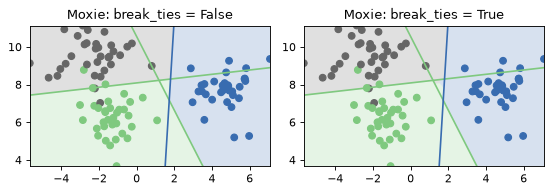

In [4]:
mx = nb.results["tie_breaking"]
fig, sub = plt.subplots(1, 2, figsize=(7, 3.4), dpi=80)
for bt, ax in zip((False, True), sub):
    pred = mx[f"pred{int(bt)}"]
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="Accent")
    ax.imshow(pred.reshape(xx.shape), cmap="Accent", alpha=0.2,
              extent=(xlim[0], xlim[1], ylim[1], ylim[0]))
    line = np.linspace(X[:, 1].min() - 5, X[:, 1].max() + 5)
    for coef, intercept, col in zip(mx[f"coef{int(bt)}"], mx[f"intercept{int(bt)}"], [(0, 1), (0, 2), (1, 2)]):
        ax.plot(-(line * coef[1] + intercept) / coef[0], line, "-", c=plt.cm.Accent([0, 4, 7][col[0]]))
    ax.set_xlim(xlim); ax.set_ylim(ylim); ax.set_aspect("equal")
    ax.set_title(f"Moxie: break_ties = {bt}")
plt.tight_layout()
plt.show()

moxie_nb.side_by_side(sklearn_coef=sk_models[True].coef_, moxie_coef=mx["coef1"],
                      sklearn_intercept=sk_models[True].intercept_, moxie_intercept=mx["intercept1"])

SOLVER = ("same LIBSVM SMO (working-set selection, shrinking, tol=1e-3) in Float64; kernel dot products "
          "and gradient updates use a different summation order, so the converged duals differ by "
          "rounding only (family parity uses rtol 3e-5 / atol 3e-6 for the same reason)")
for bt in (False, True):
    t, sk = int(bt), sk_models[bt]
    nb.compare(f"break_ties={bt}: grid predict (1e6 points)", sk_pred[bt], mx[f"pred{t}"], exact=True)
    nb.compare(f"break_ties={bt}: classes_", sk.classes_, mx[f"classes{t}"], exact=True)
    nb.compare(f"break_ties={bt}: support_", sk.support_, mx[f"support{t}"], exact=True)
    nb.compare(f"break_ties={bt}: n_support_", sk.n_support_, mx[f"n_support{t}"], exact=True)
    nb.compare(f"break_ties={bt}: n_iter_", sk.n_iter_, mx[f"n_iter{t}"], exact=True)
    nb.compare(f"break_ties={bt}: support_vectors_", sk.support_vectors_, mx[f"support_vectors{t}"], exact=True)
    nb.compare(f"break_ties={bt}: dual_coef_", sk.dual_coef_, mx[f"dual_coef{t}"], rtol=3e-5, atol=3e-6, reason=SOLVER)
    nb.compare(f"break_ties={bt}: intercept_", sk.intercept_, mx[f"intercept{t}"], rtol=3e-5, atol=3e-6, reason=SOLVER)
    nb.compare(f"break_ties={bt}: coef_", sk.coef_, mx[f"coef{t}"], rtol=3e-5, atol=3e-6, reason=SOLVER)
    nb.compare(f"break_ties={bt}: score", [sk.score(X, y)], mx[f"score{t}"], exact=True)
    nb.compare(f"break_ties={bt}: fit_status_, shape_fit_, n_features_in_",
               [sk.fit_status_, *sk.shape_fit_, sk.n_features_in_], mx[f"fit_meta{t}"], exact=True)
    nb.compare(f"break_ties={bt}: dtypes (support_ int32, dual_coef_ float64)",
               [str(sk.support_.dtype), str(sk.dual_coef_.dtype)],
               [str(mx[f"support{t}"].dtype), str(mx[f"dual_coef{t}"].dtype)], exact=True)
nb.compare("decision_function ovr (n, 3)", sk_ovr, mx["ovr"], rtol=3e-5, atol=3e-6, reason=SOLVER)
nb.compare("decision_function ovo (n, 3 pairs)", sk_ovo, mx["ovo"], rtol=3e-5, atol=3e-6, reason=SOLVER)
nb.note("break_ties + ovo", "PASS", "both raise ValueError on predict (see the two printed messages)")

## 4. Composition

`make_pipeline(StandardScaler(), SVC(kernel="linear", break_ties=True))` fitted on the blobs, a `clone` of it
refitted, and the multiclass meta-estimator wrapping that scikit-learn users reach for next.
Float64 labels are used here because `moxie.pipeline` forwards the final estimator's `List[Float64]` target.

In [5]:
from sklearn.base import clone as sk_clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sk_pipe = make_pipeline(StandardScaler(), SVC(kernel="linear", break_ties=True)).fit(X, y)
sk_pipe_pred = sk_pipe.predict(grid)
sk_pipe_dec = sk_pipe.decision_function(X)
sk_clone_pred = sk_clone(sk_pipe).fit(X, y).predict(X)

In [6]:
%%mojo pipeline
import numojo as nm
from moxie.base import clone
from moxie.pipeline import make_pipeline
from moxie.preprocessing import StandardScaler
from moxie.svm import SVC
from moxie_nb_io import load, load_ints, save, save_floats


def main() raises:
    var X = load("X")
    var grid = load("grid")
    var y = List[Float64]()
    for v in load_ints("y"):
        y.append(Float64(v))
    var pipe = make_pipeline(StandardScaler(), SVC(kernel="linear", break_ties=True))
    _ = pipe.fit(X, y)
    save_floats("pred", pipe.predict(grid))
    save("decision", pipe.decision_function(X))
    var fresh = clone(pipe)
    print("clone fitted before fit:", fresh.estimator.__sklearn_is_fitted__())
    _ = fresh.fit(X, y)
    save_floats("clone_pred", fresh.predict(X))

clone fitted before fit: False


In [7]:
pm = nb.results["pipeline"]
nb.compare("pipeline grid predict", sk_pipe_pred, pm["pred"], exact=True)
nb.compare("pipeline decision_function", sk_pipe_dec, pm["decision"], rtol=3e-5, atol=3e-6, reason=SOLVER)
nb.compare("clone(pipeline) refit predict", sk_clone_pred, pm["clone_pred"], exact=True)

True

`OneVsRestClassifier(SVC())` is a common wrapper (for example in `miscellaneous/plot_multilabel.py`). Moxie's
multiclass components must take `NDArray` targets and return `NDArray` decisions, while `SVC` takes typed
`List[Label]` targets, so the program below does not compile. This is tracked by the multiclass family
(tracking PR #12 part 1), not by an SVM defect.

In [8]:
%%mojo ovr_svc --expect-fail
from moxie.multiclass import OneVsRestClassifier
from moxie.svm import SVC
from moxie_nb_io import load


def main() raises:
    var X = load("X")
    var model = OneVsRestClassifier(SVC())
    _ = model.fit(X, load("y"))

Expected failure (unsupported in Moxie):
compilation failed
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/svm/plot_svm_tie_breaking/ovr_svc.mojo:8:36: error: no matching function in initialization
    var model = OneVsRestClassifier(SVC())
                ~~~~~~~~~~~~~~~~~~~^~~~~~~
Imported from /home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/svm/plot_svm_tie_breaking/ovr_svc.mojo:1:
Imported from /home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/deps/moxie/multiclass.mojo:12:
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/deps/moxie/_multiclass_ovr.mojo:143:9: note: candidate not viable: value passed to 'estimator' cannot be converted from 'SVC' to 'E', argument type 'SVC' does not conform to trait 'Predictor & SupervisedEstimator & Copyable & Deinitable'
    def __init__(
        ^
Imported from /home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/svm/plot_svm

In [9]:
nb.note("OneVsRestClassifier(SVC())", "GAP",
        "SVC targets are List[Label]; multiclass components need NDArray targets (multiclass PR #12 part 1)")
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
break_ties=False: grid predict (1e6 points),PASS,"(1000000,)","(1000000,)",,,exact,0 mismatches,
break_ties=False: classes_,PASS,"(3,)","(3,)",,,exact,0 mismatches,
break_ties=False: support_,PASS,"(14,)","(14,)",,,exact,0 mismatches,
break_ties=False: n_support_,PASS,"(3,)","(3,)",,,exact,0 mismatches,
break_ties=False: n_iter_,PASS,"(3,)","(3,)",,,exact,0 mismatches,
break_ties=False: support_vectors_,PASS,"(14, 2)","(14, 2)",,,exact,0 mismatches,
break_ties=False: dual_coef_,PASS,"(2, 14)","(2, 14)",0,0,"rtol=3e-05, atol=3e-06",,"same LIBSVM SMO (working-set selection, shrinking, tol=1e-3) in Float64; kernel dot products and gradient updates use a different summation order, so the converged duals differ by rounding only (family parity uses rtol 3e-5 / atol 3e-6 for the same reason)"
break_ties=False: intercept_,PASS,"(3,)","(3,)",0,0,"rtol=3e-05, atol=3e-06",,"same LIBSVM SMO (working-set selection, shrinking, tol=1e-3) in Float64; kernel dot products and gradient updates use a different summation order, so the converged duals differ by rounding only (family parity uses rtol 3e-5 / atol 3e-6 for the same reason)"
break_ties=False: coef_,PASS,"(3, 2)","(3, 2)",4.44e-15,3.6e-15,"rtol=3e-05, atol=3e-06",,"same LIBSVM SMO (working-set selection, shrinking, tol=1e-3) in Float64; kernel dot products and gradient updates use a different summation order, so the converged duals differ by rounding only (family parity uses rtol 3e-5 / atol 3e-6 for the same reason)"
break_ties=False: score,PASS,"(1,)","(1,)",,,exact,0 mismatches,
